<div style="padding: 28px 32px;
            font-family: 'Georgia', serif;">

  <p style="margin:0; font-size:13px; letter-spacing:3px; text-transform:uppercase; color:#b0477d;">
     Statistics for Data Analytics · CA2 
  </p>

  <h1 style="margin:8px 0 4px 0; font-size:32px;">
    Credit Card Limits
  </h1>

  <p style="margin:4px 0; font-size:15px;"><b>Student:</b> María Fernanda López Díaz</p>
  <p style="margin:4px 0; font-size:15px;"><b>Student ID:</b> 2026794</p>
  <p style="margin:4px 0; font-size:15px;"><b>Lecturer:</b> </p>
  <p style="margin:4px 0; font-size:15px;"><b>GitHub:</b>
    <a href="https://github.com/mafs794/payments-statistical-techniques-ca1.git" style="color:#b0477d;">
      github.com/mafs794/payments-statistical-techniques-ca1.git</a></p>
</div>

In [1]:
import pandas as pd 
from scipy import stats
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
def describe_var(col, df):
    s = df[col].dropna()
    stats = {
        "mean": s.mean(),
        "median": s.median(),
        "mode": s.mode()[0],        # [0] = first mode only (mode() returns a list)
        "min": s.min(),
        "max": s.max(),
        "range": s.max() - s.min(),
        "variance": s.var(),
        "std": s.std(),
        "Q1": s.quantile(0.25),
        "Q3": s.quantile(0.75),
        "IQR": s.quantile(0.75) - s.quantile(0.25),
        "skewness": s.skew(),
        "kurtosis": s.kurt(),
    }
    return pd.Series(stats, name=col).round(2)

def freq_table(col, df):
    counts = df[col].value_counts()
    return pd.DataFrame({"count": counts,
                         "percent": (counts / len(df) * 100).round(1)})

In [3]:
raw_data = pd.read_excel("../data/raw/credit_card_clients.xls", sheet_name="Data", header=1)

In [4]:
raw_data

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,29996,220000,1,3,1,39,0,0,0,0,...,88004,31237,15980,8500,20000,5003,3047,5000,1000,0
29996,29997,150000,1,3,2,43,-1,-1,-1,-1,...,8979,5190,0,1837,3526,8998,129,0,0,0
29997,29998,30000,1,2,2,37,4,3,2,-1,...,20878,20582,19357,0,0,22000,4200,2000,3100,1
29998,29999,80000,1,3,1,41,1,-1,0,0,...,52774,11855,48944,85900,3409,1178,1926,52964,1804,1


In [5]:
process_data = raw_data.copy()

# Rename for clarity: there is no PAY_1 in the original file, and the target name is long
process_data = process_data.rename(columns={"PAY_0": "PAY_1",
                                            "default payment next month": "default"})

# Undocumented codes: group them into "Other"
process_data["EDUCATION"] = process_data["EDUCATION"].replace({0: 4, 5: 4, 6: 4})
process_data["MARRIAGE"] = process_data["MARRIAGE"].replace({0: 3})

# Readable labels for tables and plots
process_data["sex_label"] = process_data["SEX"].map({1: "Male", 2: "Female"})
process_data["education_label"] = process_data["EDUCATION"].map(
    {1: "Graduate school", 2: "University", 3: "High school", 4: "Other"})
process_data["marriage_label"] = process_data["MARRIAGE"].map({1: "Married", 2: "Single", 3: "Other"})
process_data["default_label"] = process_data["default"].map({0: "No", 1: "Yes"})

<div style="border-left:6px solid #f06fa8; border-radius:12px;
            padding:16px 22px; margin-top:24px; font-family:'Georgia', serif;">
  <h2 style="margin:0 0 6px 0; color:#7a4a6a;">1. Descriptive Stats and Visualisation</h2>
  <p style="margin:0; font-size:15px; line-height:1.6;">
    In this section I 
  </p>
</div>

In [6]:
process_data.shape

(30000, 29)

The data contains 30,000 observations and 24 features plus the target.

In [7]:
process_data.isnull().sum()

ID                 0
LIMIT_BAL          0
SEX                0
EDUCATION          0
MARRIAGE           0
AGE                0
PAY_1              0
PAY_2              0
PAY_3              0
PAY_4              0
PAY_5              0
PAY_6              0
BILL_AMT1          0
BILL_AMT2          0
BILL_AMT3          0
BILL_AMT4          0
BILL_AMT5          0
BILL_AMT6          0
PAY_AMT1           0
PAY_AMT2           0
PAY_AMT3           0
PAY_AMT4           0
PAY_AMT5           0
PAY_AMT6           0
default            0
sex_label          0
education_label    0
marriage_label     0
default_label      0
dtype: int64

In [8]:
process_data.nunique()

ID                 30000
LIMIT_BAL             81
SEX                    2
EDUCATION              4
MARRIAGE               3
AGE                   56
PAY_1                 11
PAY_2                 11
PAY_3                 11
PAY_4                 11
PAY_5                 10
PAY_6                 10
BILL_AMT1          22723
BILL_AMT2          22346
BILL_AMT3          22026
BILL_AMT4          21548
BILL_AMT5          21010
BILL_AMT6          20604
PAY_AMT1            7943
PAY_AMT2            7899
PAY_AMT3            7518
PAY_AMT4            6937
PAY_AMT5            6897
PAY_AMT6            6939
default                2
sex_label              2
education_label        4
marriage_label         3
default_label          2
dtype: int64

In [9]:
process_data.describe()

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default
count,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,30000.000000,...,30000.000000,30000.000000,30000.000000,30000.000000,3.000000e+04,30000.00000,30000.000000,30000.000000,30000.000000,30000.000000
mean,15000.500000,167484.322667,1.603733,1.842267,1.557267,35.485500,-0.016700,-0.133767,-0.166200,-0.220667,...,43262.948967,40311.400967,38871.760400,5663.580500,5.921163e+03,5225.68150,4826.076867,4799.387633,5215.502567,0.221200
std,8660.398374,129747.661567,0.489129,0.744494,0.521405,9.217904,1.123802,1.197186,1.196868,1.169139,...,64332.856134,60797.155770,59554.107537,16563.280354,2.304087e+04,17606.96147,15666.159744,15278.305679,17777.465775,0.415062
min,1.000000,10000.000000,1.000000,1.000000,1.000000,21.000000,-2.000000,-2.000000,-2.000000,-2.000000,...,-170000.000000,-81334.000000,-339603.000000,0.000000,0.000000e+00,0.00000,0.000000,0.000000,0.000000,0.000000
25%,7500.750000,50000.000000,1.000000,1.000000,1.000000,28.000000,-1.000000,-1.000000,-1.000000,-1.000000,...,2326.750000,1763.000000,1256.000000,1000.000000,8.330000e+02,390.00000,296.000000,252.500000,117.750000,0.000000
50%,15000.500000,140000.000000,2.000000,2.000000,2.000000,34.000000,0.000000,0.000000,0.000000,0.000000,...,19052.000000,18104.500000,17071.000000,2100.000000,2.009000e+03,1800.00000,1500.000000,1500.000000,1500.000000,0.000000
75%,22500.250000,240000.000000,2.000000,2.000000,2.000000,41.000000,0.000000,0.000000,0.000000,0.000000,...,54506.000000,50190.500000,49198.250000,5006.000000,5.000000e+03,4505.00000,4013.250000,4031.500000,4000.000000,0.000000
max,30000.000000,1000000.000000,2.000000,4.000000,3.000000,79.000000,8.000000,8.000000,8.000000,8.000000,...,891586.000000,927171.000000,961664.000000,873552.000000,1.684259e+06,896040.00000,621000.000000,426529.000000,528666.000000,1.000000


In [10]:
process_data.duplicated().sum()

np.int64(0)

In [11]:
num_cols = ["LIMIT_BAL", "AGE", "BILL_AMT1", "PAY_AMT1"]
pd.concat([describe_var(c, process_data) for c in num_cols], axis=1)

,LIMIT_BAL,AGE,BILL_AMT1,PAY_AMT1
mean,1.674843e+05,35.49,5.122333e+04,5.663580e+03
median,1.400000e+05,34.00,2.238150e+04,2.100000e+03
mode,5.000000e+04,29.00,0.000000e+00,0.000000e+00
min,1.000000e+04,21.00,-1.655800e+05,0.000000e+00
max,1.000000e+06,79.00,9.645110e+05,8.735520e+05
range,9.900000e+05,58.00,1.130091e+06,8.735520e+05
variance,1.683446e+10,84.97,5.422240e+09,2.743423e+08
std,1.297477e+05,9.22,7.363586e+04,1.656328e+04
Q1,5.000000e+04,28.00,3.558750e+03,1.000000e+03
Q3,2.400000e+05,41.00,6.709100e+04,5.006000e+03


- Limit-Ba: is Right-skewed: a few clients have very high limits.
- Age is the closest to normal.
- Bill AMT1: Very skewed. With a min of -165,580, negative bills mean the client overpaid.
- Pay AMT1: skew of 14.67 is highly skew with extreme outliers.


In [12]:
for col in ["sex_label", "education_label", "marriage_label", "default_label"]:
    display(freq_table(col, process_data))

,count,percent
sex_label,,
Female,18112,60.4
Male,11888,39.6


,count,percent
education_label,,
University,14030,46.8
Graduate school,10585,35.3
High school,4917,16.4
Other,468,1.6


,count,percent
marriage_label,,
Single,15964,53.2
Married,13659,45.5
Other,377,1.3


,count,percent
default_label,,
No,23364,77.9
Yes,6636,22.1


Default label is pretty imbalanced. 

In [13]:
(pd.crosstab(process_data["education_label"], process_data["default_label"],
             normalize="index") * 100).round(1)

default_label,No,Yes
education_label,,
Graduate school,80.8,19.2
High school,74.8,25.2
Other,92.9,7.1
University,76.3,23.7


In [14]:
(pd.crosstab(process_data["sex_label"], process_data["default_label"],
             normalize="index") * 100).round(1)

default_label,No,Yes
sex_label,,
Female,79.2,20.8
Male,75.8,24.2


In [15]:
(pd.crosstab(process_data["marriage_label"], process_data["default_label"],
             normalize="index") * 100).round(1)

default_label,No,Yes
marriage_label,,
Married,76.5,23.5
Other,76.4,23.6
Single,79.1,20.9


# Histogram + KDE 

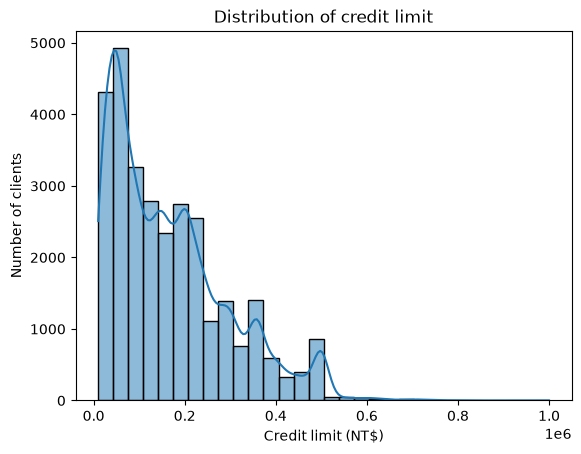

In [16]:
sns.histplot(process_data["LIMIT_BAL"], kde=True, bins=30)
plt.xlabel("Credit limit (NT$)")
plt.ylabel("Number of clients")
plt.title("Distribution of credit limit")
plt.show()

Credit Limit is righ-skewed. The mann-whitney U test and t-test can be use in this features as it is not normally distributed.

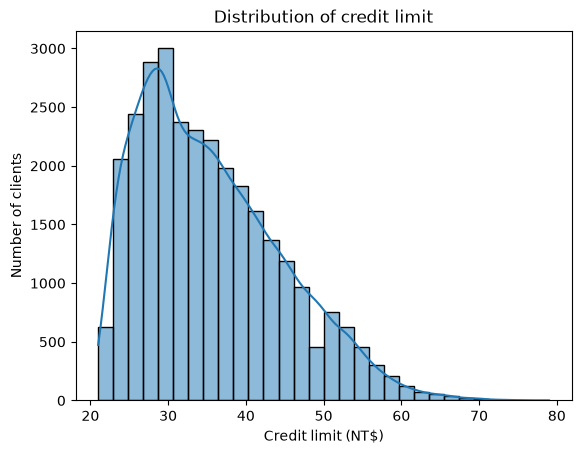

In [17]:
sns.histplot(process_data["AGE"], kde=True, bins=30)
plt.xlabel("Credit limit (NT$)")
plt.ylabel("Number of clients")
plt.title("Distribution of credit limit")
plt.show()

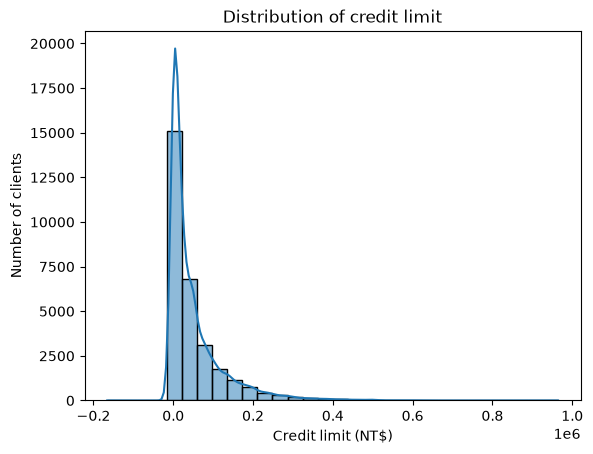

In [20]:
sns.histplot(process_data["BILL_AMT1"], kde=True, bins=30)
plt.xlabel("Credit limit (NT$)")
plt.ylabel("Number of clients")
plt.title("Distribution of credit limit")
plt.show()

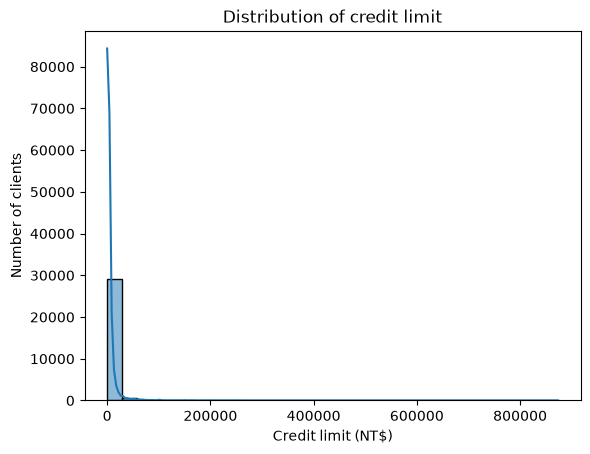

In [21]:
sns.histplot(process_data["PAY_AMT1"], kde=True, bins=30)
plt.xlabel("Credit limit (NT$)")
plt.ylabel("Number of clients")
plt.title("Distribution of credit limit")
plt.show()

# Boxplots by group

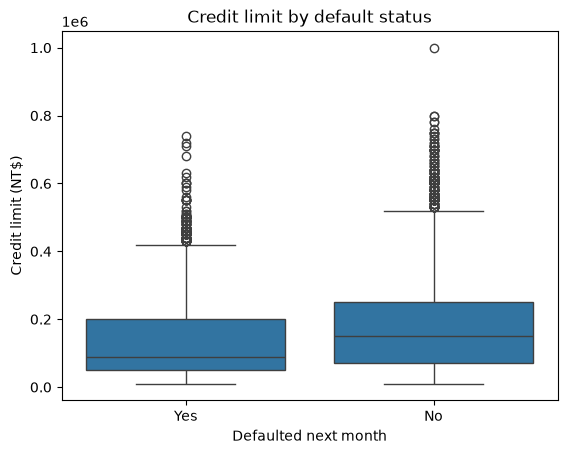

In [22]:
sns.boxplot(data=process_data, x="default_label", y="LIMIT_BAL")
plt.xlabel("Defaulted next month")
plt.ylabel("Credit limit (NT$)")
plt.title("Credit limit by default status")
plt.show()

Defaulters appear to have lower credit limits. I will test whether this
  difference is significant. The spread differs between groups, so I will use Welch's
  t-test, which does not assume equal variances.

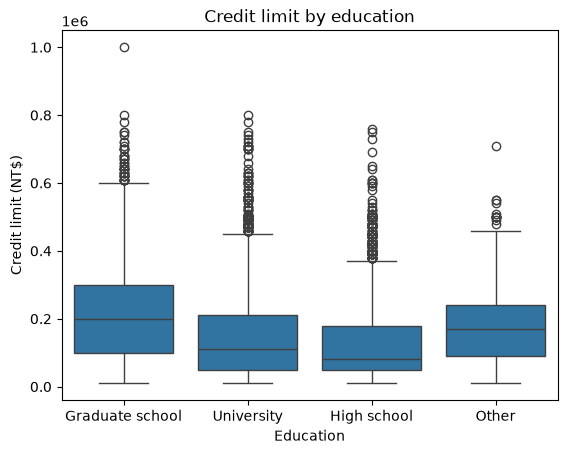

In [23]:
order = ["Graduate school", "University", "High school", "Other"]
sns.boxplot(data=process_data, x="education_label", y="LIMIT_BAL", order=order)
plt.xlabel("Education")
plt.ylabel("Credit limit (NT$)")
plt.title("Credit limit by education")
plt.show()

Credit limits seem to differ by education level. Because there are more
  than two groups, I will use ANOVA and Kruskal-Wallis.

#  bar chart of default rate

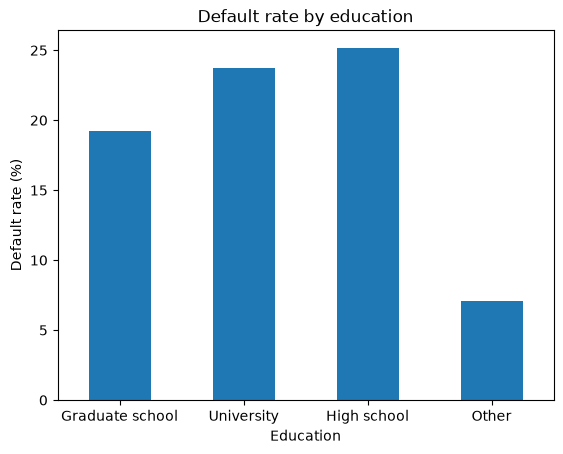

In [24]:
rate = process_data.groupby("education_label")["default"].mean().mul(100).reindex(order)
rate.plot(kind="bar")
plt.xlabel("Education")
plt.ylabel("Default rate (%)")
plt.title("Default rate by education")
plt.xticks(rotation=0)
plt.show()

Default rates appear to differ by education. Both variables are
  categorical, so I will use a chi-squared test of independence.

# Stacked bar chart

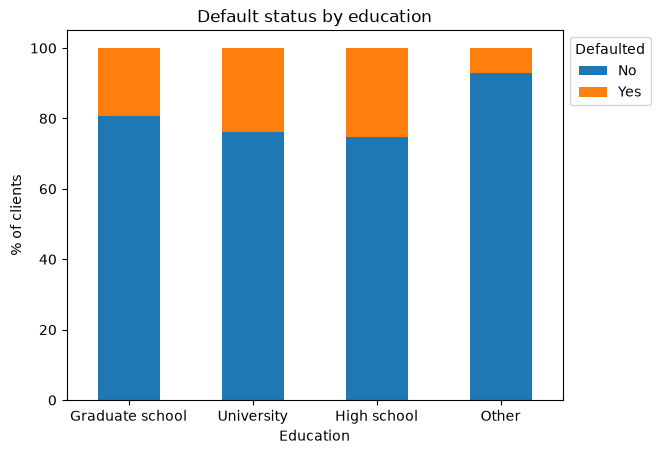

In [25]:
ct = pd.crosstab(process_data["education_label"], process_data["default_label"], normalize="index") * 100
ct.loc[order].plot(kind="bar", stacked=True)
plt.xlabel("Education")
plt.ylabel("% of clients")
plt.title("Default status by education")
plt.legend(title="Defaulted", bbox_to_anchor=(1, 1))
plt.xticks(rotation=0)
plt.show()

# correlation heatmap

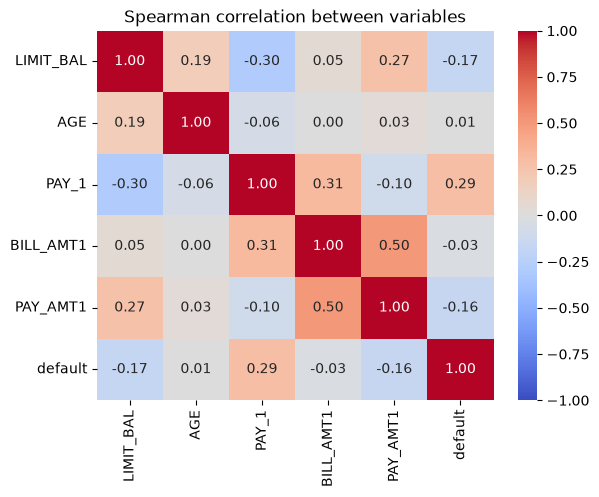

In [26]:
num_cols = ["LIMIT_BAL", "AGE", "PAY_1", "BILL_AMT1", "PAY_AMT1", "default"]
corr = process_data[num_cols].corr(method="spearman")

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Spearman correlation between variables")
plt.show()

Payment delay shows the strongest relationship with default. Because the
  variables are skewed, I used Spearman correlation instead of Pearson.

# Q-Q Plot

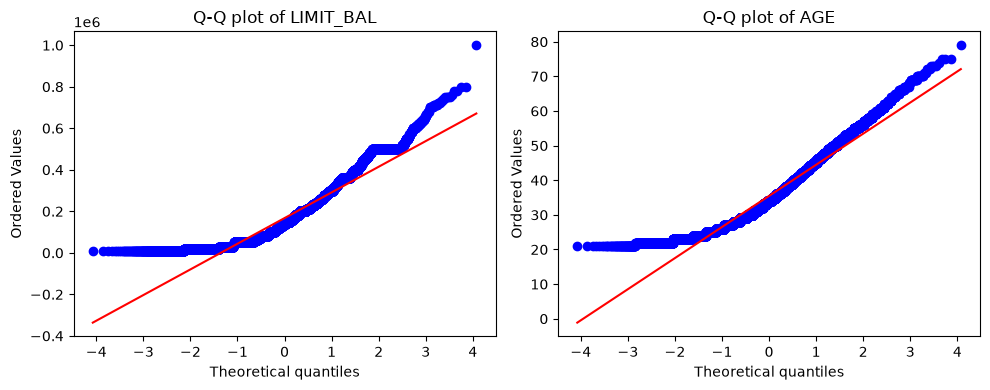

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, col in zip(ax, ["LIMIT_BAL", "AGE"]):
    stats.probplot(process_data[col], dist="norm", plot=a)
    a.set_title(f"Q-Q plot of {col}")
plt.tight_layout()
plt.show()

The Limit_Bal Q-Q plot confirms that credit limit is not normal, so the normality assumption of the t-test and ANOVA is violated.

### Key Findings
The descriptive analysis shows that the numerical variables are right-skewed and contain outliers, so the normality assumption is doubtful. For this reason, each parametric test in Task 3 will be paired with a non-parametric alternative. With n = 30,000, the Central Limit Theorem means the parametric tests are still reasonably robust (Field, 2018).

<div style="border-left:6px solid #f06fa8; border-radius:12px;
            padding:16px 22px; margin-top:24px; font-family:'Georgia', serif;">
  <h2 style="margin:0 0 6px 0; color:#7a4a6a;">2. Inferential statistics & Confidence intervals</h2>
  <p style="margin:0; font-size:15px; line-height:1.6;">
    In this section I 
  </p>
</div>

## CI for a mean (t), credit limit

In [28]:
levels = [0.90, 0.95, 0.99]

x = process_data["LIMIT_BAL"]
n = len(x)
mean = x.mean()
se = x.std() / np.sqrt(n)          # standard error

rows = []
for cl in levels:
    t_crit = stats.t.ppf((1 + cl) / 2, df=n - 1)
    margin = t_crit * se
    rows.append({"level": f"{int(cl*100)}%", "critical value": round(t_crit, 3),
                 "lower": round(mean - margin), "upper": round(mean + margin),
                 "width": round(2 * margin)})
mean_ci = pd.DataFrame(rows)
print(f"Sample mean: {mean:,.0f}")
mean_ci

Sample mean: 167,484


,level,critical value,lower,upper,width
0,90%,1.645,166252,168717,2464
1,95%,1.960,166016,168953,2937
2,99%,2.576,165555,169414,3859


## CI for a proportion (z), default rate 

In [29]:
y = process_data["default"]
n = len(y)
p_hat = y.mean()
se_p = np.sqrt(p_hat * (1 - p_hat) / n)

# Assumption check: np and n(1-p) should both be at least 10
print("np =", n * p_hat, " n(1-p) =", n * (1 - p_hat))

rows = []
for cl in levels:
    z_crit = stats.norm.ppf((1 + cl) / 2)
    margin = z_crit * se_p
    rows.append({"level": f"{int(cl*100)}%", "critical value": round(z_crit, 3),
                 "lower %": round((p_hat - margin) * 100, 2),
                 "upper %": round((p_hat + margin) * 100, 2),
                 "width %": round(2 * margin * 100, 2)})
prop_ci = pd.DataFrame(rows)
print(f"Sample default rate: {p_hat:.2%}")
prop_ci

np = 6636.0  n(1-p) = 23363.999999999996
Sample default rate: 22.12%


,level,critical value,lower %,upper %,width %
0,90%,1.645,21.73,22.51,0.79
1,95%,1.960,21.65,22.59,0.94
2,99%,2.576,21.50,22.74,1.23
